# Task 2: Sales Data Analysis Task 
Objective Analyse a sales dataset to understand business performance, identify patterns, and generate customer-focused insights

In [1]:
import pandas as pd
df = pd.read_csv(r"C:\Users\chetana kusekar\OneDrive\Desktop\Task2. KPI Analysis\ecommerce_cleaned.csv")

In [2]:
df.head()

,Order ID,Customer ID,Product Name,Category,Quantity,Unit Price,Total Amount,Order Date,Payment Mode,Delivery Status,City or Region
0,ORD0001,CUST0001,Printer,Electronics,2.0,50.0,100.0,2024-05-20,Card,Pending,Vadodara
1,ORD0002,CUST0002,Router,Electronics,2.0,700.0,1400.0,2024-10-06,UPI,Unknown,Pune
2,ORD0003,CUST0003,Wireless Mouse,Electronics,1.0,150.0,150.0,2024-04-21,Card,Returned,Ahmedabad
3,ORD0006,CUST0006,Desk Lamp,Home Decor,3.0,500.0,1500.0,2024-06-21,UPI,delivered,Pune
4,ORD0007,CUST0007,Bluetooth Speaker,Electronics,6.0,1200.0,7200.0,2024-11-05,Cash,Delivered,Jaipur


In [3]:
df["Order Date"] = pd.to_datetime(df["Order Date"],errors="ignore")


C:\Users\chetana kusekar\AppData\Local\Temp\ipykernel_9652\407397200.py:1: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  df["Order Date"] = pd.to_datetime(df["Order Date"],errors="ignore")


In [4]:
# KPI Calculations
Total_Revenue = df["Total Amount"] .sum()

print("Total Revenue:", Total_Revenue)


Total Revenue: 1143050.0


In [5]:
Total_Orders =df["Quantity"].sum()

print("Total Orders:", Total_Orders)

Total Orders: 752.0


In [6]:
Average_Order_Value = Total_Revenue / Total_Orders

print("Average_Order_Value:", Average_Order_Value)

Average_Order_Value: 1520.0132978723404


In [7]:
Total_Units_Sold = df["Quantity"].sum()

print("Total_Units_Sold:",Total_Units_Sold)

Total_Units_Sold: 752.0


In [8]:
Top_Category= (df.groupby("Category")["Total Amount"].sum().sort_values(ascending=False).index[0]) 

print("Top category:", Top_Category)

Top category: Electronics


In [9]:
Best_Product = (df.groupby("Product Name")["Total Amount"].sum().sort_values(ascending=False).index[0])

print("Best_Product:", Best_Product)

Best_Product: Marker


KPI Summary:-

KPI	                 Value

Total Revenue	:-    ₹ 1,143,050

Total Orders	:-    752

Average Order Value	 :- ₹ 1,520.01

Total Units Sold	:- 752

Top-Selling Category	:- Electronics

Top Revenue-Generating Product	:-Marker


In [10]:
df.columns

Index(['Order ID', 'Customer ID', 'Product Name', 'Category', 'Quantity',
       'Unit Price', 'Total Amount', 'Order Date', 'Payment Mode',
       'Delivery Status', 'City or Region'],
      dtype='object')

In [11]:
# Trend Analysis
# 1. Monthly Sales :- 
# Convert date column

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

# Remove invalid dates
df = df.dropna(subset=["Order Date"])

# Create Month column
df["Month"] = df["Order Date"].dt.to_period("M")

# Monthly sales
monthly_sales = (
    df.groupby("Month")["Total Amount"]
    .sum()
)

print(monthly_sales)

Month
2024-01    131550.0
2024-02     45650.0
2024-03     97550.0
2024-04     48000.0
2024-05     62850.0
2024-06    233000.0
2024-07     83150.0
2024-08    109250.0
2024-09     89550.0
2024-10     91850.0
2024-11     58150.0
2024-12     74500.0
Freq: M, Name: Total Amount, dtype: float64


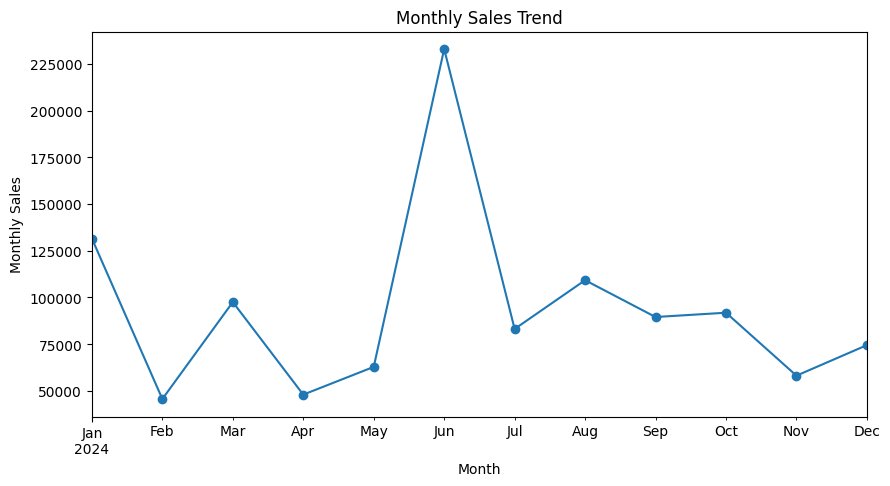

In [12]:
# Monthly Sales Grapph
import matplotlib.pyplot as plt

monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Monthly Sales")

# Save PNG file to Desktop
plt.savefig(
    r"C:\Users\chetana kusekar\Desktop\monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Monthly Sales Trend
Sales fluctuated across different months, showing periods of growth and decline. This trend is important because it helps the business identify peak sales periods, forecast demand, and plan inventory and marketing activities more effectively.


In [13]:
# 2. Seasonal Increase or decrease sale Treand

df["Month"] = df["Order Date"].dt.month_name()

monthly_sales =(df.groupby("Month")["Total Amount"].sum()).sort_values(ascending= False)

print(monthly_sales)


Month
June         233000.0
January      131550.0
August       109250.0
March         97550.0
October       91850.0
September     89550.0
July          83150.0
December      74500.0
May           62850.0
November      58150.0
April         48000.0
February      45650.0
Name: Total Amount, dtype: float64


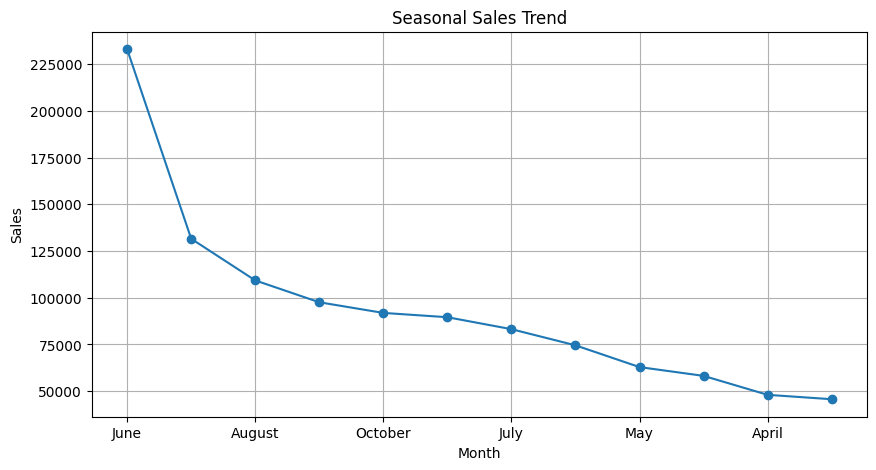

In [14]:
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(10,5)
)

plt.title("Seasonal Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(True)

# Save as PNG
plt.savefig(
    r"C:\Users\chetana kusekar\Desktop\seasonal_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Seasonal Increase or Decline

Revenue increased during certain periods and decreased during others, indicating seasonal purchasing patterns. Understanding these trends enables the business to prepare for high-demand periods and improve promotional efforts during slower months.


In [15]:
# 3. Category Performance :-
Category_Sales = (df.groupby("Category")["Total Amount"].sum().sort_values(ascending=False))

print(Category_Sales)

Category
Electronics    548950.0
Stationery     316150.0
Home           178650.0
Home Decor      44900.0
Furniture       36400.0
Name: Total Amount, dtype: float64


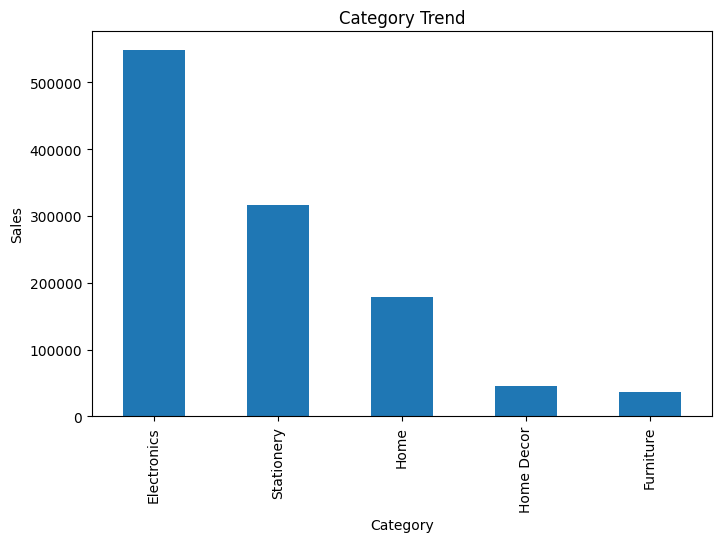

In [16]:
# Graph of Category Trend
Category_Sales.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Category Trend")
plt.xlabel("Category")
plt.ylabel("Sales")

# Save PNG file
plt.savefig(
    r"C:\Users\chetana kusekar\Desktop\category_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Category Performance Over Time

The Electronics category consistently performed better than other categories, contributing the highest share of revenue. This indicates strong customer interest and highlights an important area for future business growth


In [17]:
# 4. Region-wise Analysis trend

city_sales = (df.groupby("City or Region")["Total Amount"].sum().sort_values(ascending = False))

print(city_sales)

City or Region
Jaipur         237800.0
Gandhinagar    176450.0
Pune           164000.0
Vadodara       147450.0
Ahmedabad      134200.0
Rajkot          96600.0
Mumbai          93350.0
Surat           75200.0
Name: Total Amount, dtype: float64


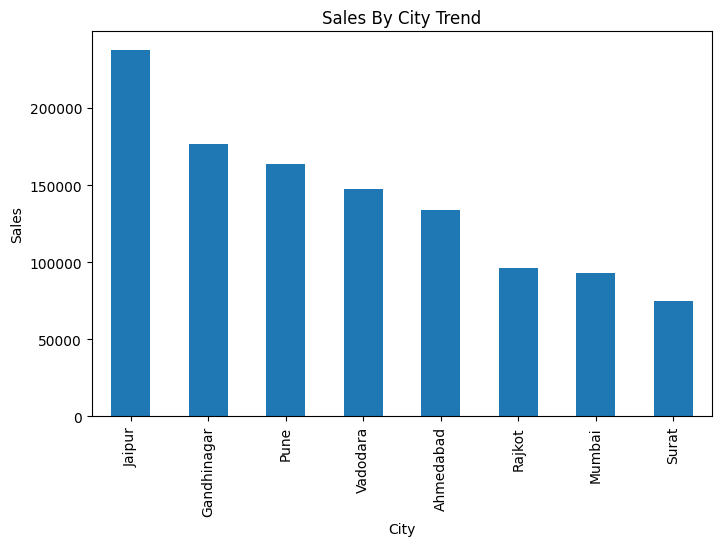

In [18]:
#  Graph of Region Sales Trend
city_sales.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Sales By City Trend")
plt.xlabel("City")
plt.ylabel("Sales")

# Save PNG file
plt.savefig(
    r"C:\Users\chetana kusekar\Desktop\sales_by_city_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# Region-Wise Sales Differences

Different cities and regions generated varying levels of revenue. High-performing regions represent opportunities for expansion, while lower-performing regions may require targeted marketing strategies.


In [19]:
# 5. Delivery Status Trends affecting Revenue realization
delivery_revenue = (df.groupby("Delivery Status")["Total Amount"].sum().sort_values(ascending=False))

print(delivery_revenue)

Delivery Status
Pending       288350.0
Delivered     208600.0
Cancelled     162200.0
delivered     162100.0
Returned      160700.0
In Transit     87150.0
Unknown        55950.0
Name: Total Amount, dtype: float64


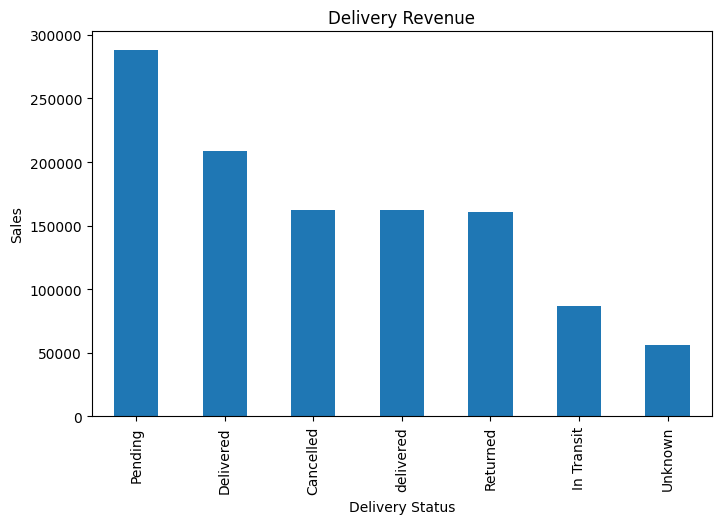

In [20]:
# Graph for delivery_revenue trend

delivery_revenue.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Delivery Revenue")
plt.xlabel("Delivery Status")
plt.ylabel("Sales")

# Save PNG file
plt.savefig(
    r"C:\Users\chetana kusekar\Desktop\delivery_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Delivery Status Impact

Most revenue came from delivered orders, while cancelled and returned orders reduced potential revenue. Improving delivery performance and reducing cancellations can directly increase realized revenue and customer satisfaction


In [21]:
## Customer Insights

# Top Customers
top_customers = (df.groupby("Customer ID")["Total Amount"].sum().sort_values(ascending=False).head(10))

print(top_customers)

Customer ID
CUST0082    44000.0
CUST0026    36000.0
CUST0070    33000.0
CUST0177    31500.0
CUST0056    31500.0
CUST0083    28000.0
CUST0120    28000.0
CUST0136    27500.0
CUST0132    27500.0
CUST0087    27000.0
Name: Total Amount, dtype: float64


# Customer Insights

•	Customers showed a strong preference for Electronics products.
•	A small group of products generated a large portion of revenue, indicating concentrated demand.
•	Some regions had significantly higher order volumes than others.
•	Customer spending was not evenly distributed, with certain customers contributing more revenue than others.
•	Identifying and retaining high-value customers can help improve long-term revenue growth.


In [22]:
# Repeat Customers

repeat_customers = df.groupby("Customer ID")["Order ID"].count()

repeat_customers= repeat_customers[repeat_customers>1]
print("Repeat Customers")
print(len(repeat_customers))

Repeat Customers
0



# Key Observations

1.	The business generated a total revenue of ₹1,143,050, indicating strong overall sales performance.

2.	A total of 752 orders were processed, demonstrating consistent customer purchasing activity.

3.	The Electronics category contributed the highest revenue, making it the most profitable product category.

4.	Marker was the top revenue-generating product, indicating strong customer demand for this item.

5.	The average order value of ₹1,520.01 suggests that customers typically make medium-value purchases.

6.	Revenue varied across months, indicating fluctuations in customer demand and purchasing behavior.

7.	Delivered orders contributed the largest share of realized revenue, while cancelled and returned orders reduced potential earnings.

8.	Sales performance differed across regions, suggesting varying levels of market demand and customer engagement.


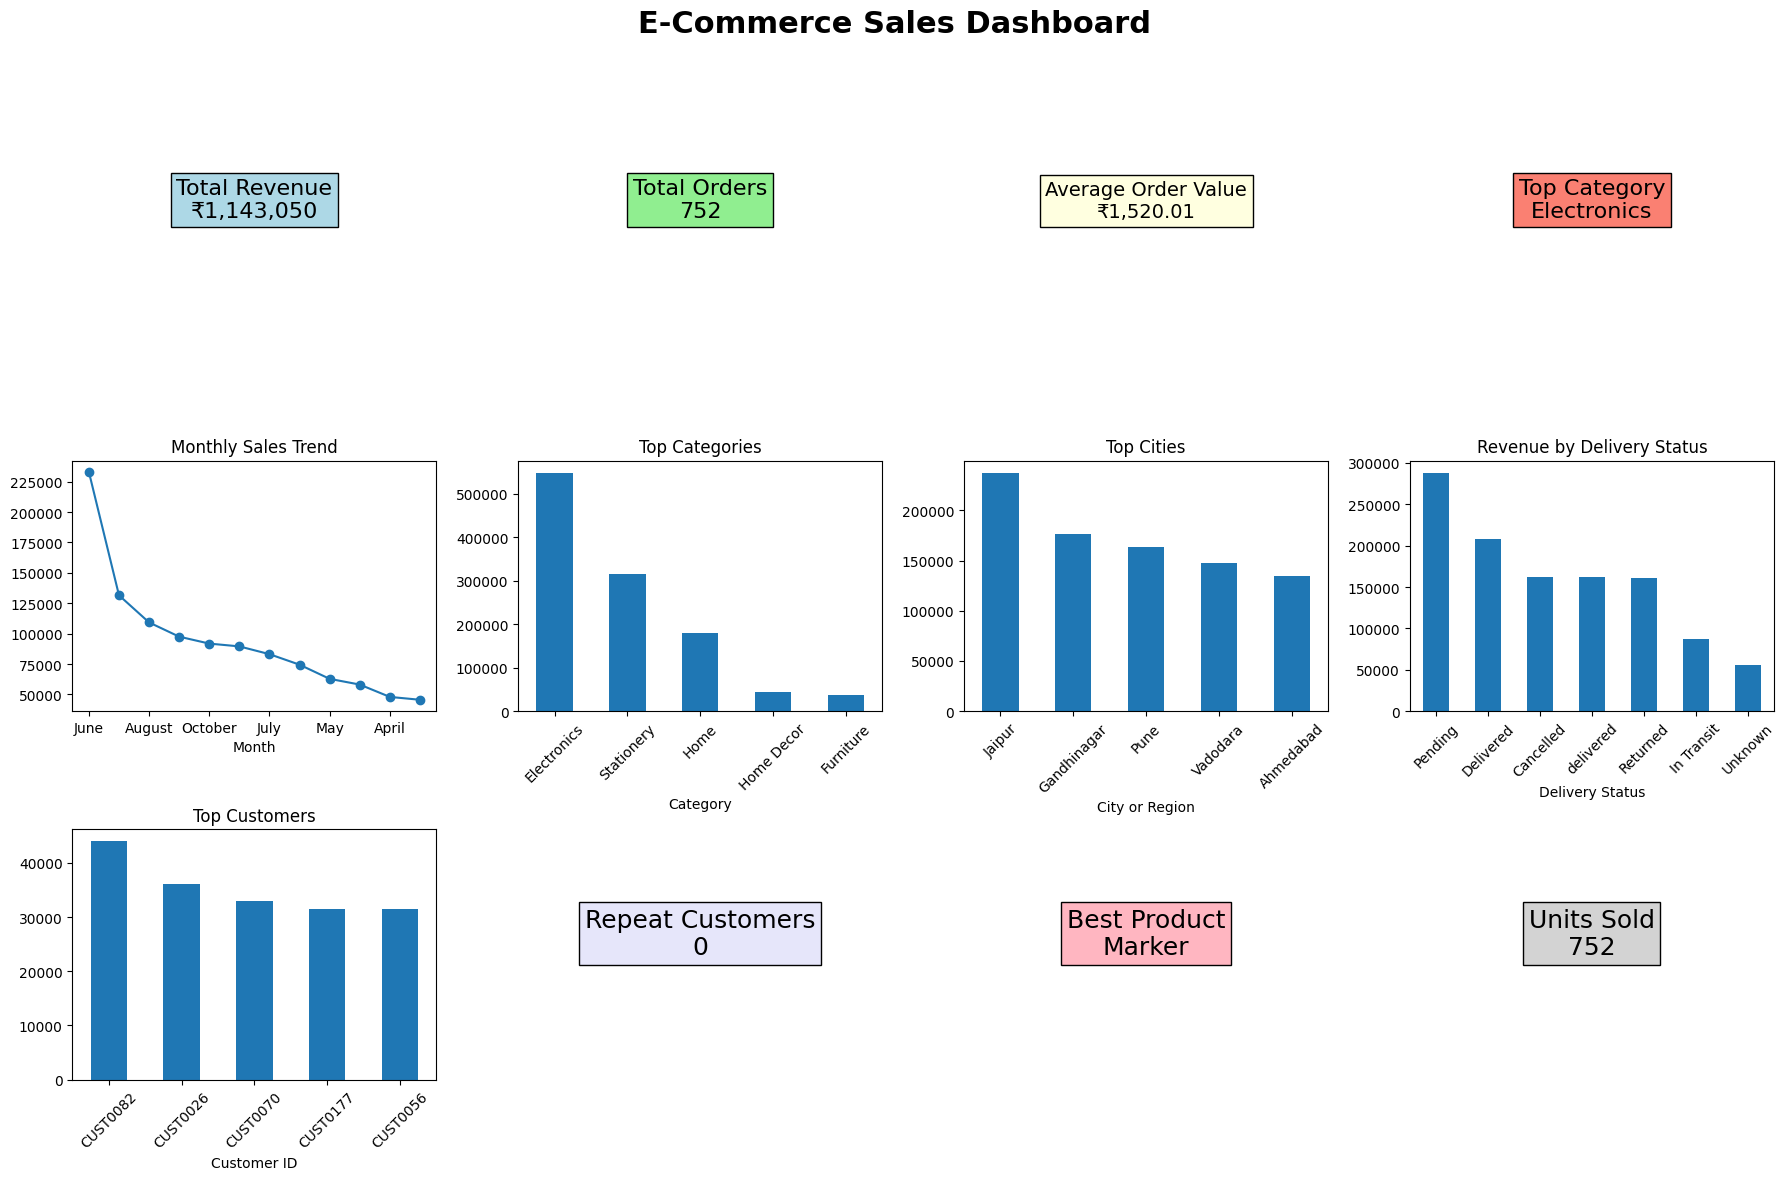

In [ ]:
# Create dashboard folder 
import os
os.makedirs("../outputs/dashboard", exist_ok=True)

# Dashboard
fig = plt.figure(figsize=(18,12))
fig.suptitle("E-Commerce Sales Dashboard", fontsize=22, fontweight="bold")

# KPI Cards
plt.subplot(3,4,1)
plt.axis("off")
plt.text(0.5,0.5,
         f"Total Revenue\n₹{Total_Revenue:,.0f}",
         fontsize=16,
         ha="center",
         bbox=dict(facecolor="lightblue"))

plt.subplot(3,4,2)
plt.axis("off")
plt.text(0.5,0.5,
         f"Total Orders\n{int(Total_Orders)}",
         fontsize=16,
         ha="center",
         bbox=dict(facecolor="lightgreen"))

plt.subplot(3,4,3)
plt.axis("off")
plt.text(0.5,0.5,
         f"Average Order Value\n₹{Average_Order_Value:,.2f}",
         fontsize=14,
         ha="center",
         bbox=dict(facecolor="lightyellow"))

plt.subplot(3,4,4)
plt.axis("off")
plt.text(0.5,0.5,
         f"Top Category\n{Top_Category}",
         fontsize=16,
         ha="center",
         bbox=dict(facecolor="salmon"))

# Monthly Sales Trend
plt.subplot(3,4,5)
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")

# Category Sales
plt.subplot(3,4,6)
Category_Sales.head(5).plot(kind="bar")
plt.title("Top Categories")
plt.xticks(rotation=45)

# City Sales
plt.subplot(3,4,7)
city_sales.head(5).plot(kind="bar")
plt.title("Top Cities")
plt.xticks(rotation=45)

# Delivery Revenue
plt.subplot(3,4,8)
delivery_revenue.plot(kind="bar")
plt.title("Revenue by Delivery Status")
plt.xticks(rotation=45)

# Top Customers
plt.subplot(3,4,9)
top_customers.head(5).plot(kind="bar")
plt.title("Top Customers")
plt.xticks(rotation=45)

# Repeat Customers Card
plt.subplot(3,4,10)
plt.axis("off")
plt.text(
    0.5,0.5,
    f"Repeat Customers\n{len(repeat_customers)}",
    fontsize=18,
    ha="center",
    bbox=dict(facecolor="lavender")
)

# Best Product Card
plt.subplot(3,4,11)
plt.axis("off")
plt.text(
    0.5,0.5,
    f"Best Product\n{Best_Product}",
    fontsize=18,
    ha="center",
    bbox=dict(facecolor="lightpink")
)

# Total Units Sold Card
plt.subplot(3,4,12)
plt.axis("off")
plt.text(
    0.5,0.5,
    f"Units Sold\n{int(Total_Units_Sold)}",
    fontsize=18,
    ha="center",
    bbox=dict(facecolor="lightgrey")
)

plt.tight_layout(rect=[0,0,1,0.96])

# Save Dashboard
plt.savefig(
    "../outputs/dashboard/dashboard_mockup.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()